# Forward models for the Montreal River Monocline

### Import Python packages

In [1]:
import numpy as np
import pandas as pd
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
import matplotlib.pyplot as plt
import pythermo as pyt

%matplotlib inline
%config InlineBackend.figure_format='retina'

### Load data from csv files

In [2]:
zircon_data = pd.read_csv("data/UTh_He_zircon_data.csv")
apatite_data = pd.read_csv("data/UTh_He_apatite_data.csv")

### High grade to data sets for forward model comparison

Get the zircon data first

In [5]:
# Split the 'Unnamed: 0' column which has the analysis name into three parts
splits_z = zircon_data['Unnamed: 0'].str.split('_', expand=True)
splits_a = apatite_data['Unnamed: 0'].str.split('_', expand=True)


# Assign the second part (index 1) to the new 'sample' column
zircon_data['sample'] = splits_z[1]
apatite_data['sample'] = splits_a[1]

# Assign the third part (index 2) to the new 'grain' column
zircon_data['grain'] = splits_z[2]
apatite_data['grain'] = splits_a[2]

MRM_Archean_samples = ['MRM1','MRM2','MRM4','MRM5','MRM6','MRM35','MRM20',
                       'MRM8','MRM17','MRM16','MRM7','MRM21', 'MRM36']

Other_Archean_samples = ['MRM24']
 
MRM_rift_samples = ['MRM9', 'MRM34', 'MC4']

MRM_Freda_samples = ['LRA','BRB']

MRM_Archean_data = zircon_data[zircon_data['sample'].isin(MRM_Archean_samples)]
Other_Archean_data = zircon_data[zircon_data['sample'].isin(Other_Archean_samples)]
MRM_rift_data = zircon_data[zircon_data['sample'].isin(MRM_rift_samples)]
MRM_Freda_data = zircon_data[zircon_data['sample'].isin(MRM_Freda_samples)]

Now get the apatite data

In [7]:
apatite_data['sample'] = apatite_data['sample'].replace('397', 'MC4')

MRM_apatite_samples = ['MRM35', 'MRM36', 'MC4', 'MRM16', 'MRM8', 'MRM6', 'MRM20', 'MRM21', 'MRM24']
MRM_apatite_samples_selected = ['MRM35', 'MRM36', 'MC4', 'MRM8', 'MRM6', 'MRM21', 'MRM24']

MRM_apatite_data = apatite_data[apatite_data['sample'].isin(MRM_apatite_samples_selected)]

Load the data into arrays formatted for input into PyThermo

In [9]:
ap_obs_data = np.zeros((13,4))

ap_obs_data[:,0] = MRM_apatite_data['corrected_date']
ap_obs_data[:,1] = MRM_apatite_data['corrected_1s']
ap_obs_data[:,2] = MRM_apatite_data['eU']
ap_obs_data[:,3] = MRM_apatite_data['radius']

zirc_obs_data = np.zeros((56,4))

zirc_obs_data[:,0] = MRM_Archean_data['corrected_date']
zirc_obs_data[:,1] = MRM_Archean_data['corrected_1s']
zirc_obs_data[:,2] = MRM_Archean_data['eU']
zirc_obs_data[:,3] = MRM_Archean_data['radius']

### Create input model data frame and tT arrays

Model data frame first

In [10]:
ap_dict = {'mineral type':['apatite', 'apatite', 'apatite','apatite','apatite','apatite','apatite'], 'age':[60,80,90,0,0,0,0],'error':[2,2,2,0,0,0,0],'size':[60,60,60,60,60,60,60],'U ppm':[10,20,40,60,80,100,125],'Th ppm':[0,0,0,0,0,0,0],'Sm ppm':[0,0,0,0,0,0,0],'diffusion model':['flowers','flowers','flowers','flowers','flowers','flowers','flowers'],'annealing model':['ketcham','ketcham','ketcham','ketcham','ketcham','ketcham','ketcham']}

ap_grain_in = pd.DataFrame(data=ap_dict,
                        columns = ['mineral type', 'age', 'error','size','U ppm', 'Th ppm', 'Sm ppm', 'diffusion model', 'annealing model'],
                        index = ['ap 1', 'ap 2', 'ap 3','ap 4','ap 5','ap 6', 'ap 7'])

zirc_dict = {'mineral type':['zircon', 'zircon', 'zircon','zircon','zircon','zircon','zircon','zircon','zircon'], 'age':[60,80,90,0,0,0,0,0,0],'error':[2,2,2,0,0,0,0,0,0],'size':[60,60,60,60,60,60,60,60,60],'U ppm':[50,100,250,500,750,1000,1250,1500,2000],'Th ppm':[0,0,0,0,0,0,0,0,0],'Sm ppm':[0,0,0,0,0,0,0,0,0],'diffusion model':['guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner'],'annealing model':['guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner']}

zirc_grain_in = pd.DataFrame(data=zirc_dict,
                        columns = ['mineral type', 'age', 'error','size','U ppm', 'Th ppm', 'Sm ppm', 'diffusion model', 'annealing model'],
                        index = ['zirc 1', 'zirc 2', 'zirc 3','zirc 4','zirc 5','zirc 6', 'zirc 7', 'zirc 8', 'zirc 9'])

Time-temperature path arrays are below... sandbox approach until final figures are decided upon

In [74]:
#apatite models

tT_ap_phan = np.array([[0,10,0,10,0,10,0,10],[250,75,250,80,250,85,250,90],[505,10,505,10,505,10,505,10],[990,75,990,75,990,75,990,75],[1040,10,1040,10,1040,10,1040,10],[1050,160,1050,160,1050,160,1050,160],])

tT_ap_neo_heat = np.array([[0,10,0,10,0,10],[250,80,250,80,250,80],[505,10,505,10,505,10],[990,65,990,75,990,85],[1040,10,1040,10,1040,10],[1050,160,1050,160,1050,160],])

tT_ap_neo_cool = np.array([[0,10,0,10,0,10,0,10],[250,80,250,80,250,80,250,80],[505,10,505,10,505,10,505,10],[550,75,650,75,750,75,850,75],[990,75,990,75,990,75,990,75],[1040,10,1040,10,1040,10,1040,10],[1050,160,1050,160,1050,160,1050,160],])

tT_ap_550Ma = np.array([[0,10,0,10,0,10],[250,80,250,80,250,80],[505,10,505,10,505,10],[550,65,550,75,550,85],[990,65,990,75,990,85],[1040,10,1040,10,1040,10],[1050,160,1050,160,1050,160],])

tT_ap_750Ma = np.array([[0,10,0,10,0,10],[250,80,250,80,250,80],[505,10,505,10,505,10],[750,65,750,75,750,85],[990,65,990,75,990,85],[1040,10,1040,10,1040,10],[1050,160,1050,160,1050,160],])

tT_ap_850Ma = np.array([[0,10,0,10,0,10],[250,80,250,80,250,80],[505,10,505,10,505,10],[850,65,850,75,850,85],[990,65,990,75,990,85],[1040,10,1040,10,1040,10],[1050,160,1050,160,1050,160],])

#zircon models

tT_zirc_phan = np.array([[0,10,0,10,0,10,0,10],[250,75,250,80,250,85,250,90],[505,10,505,10,505,10,505,10],[990,75,990,75,990,75,990,75],[1040,10,1040,10,1040,10,1040,10],[1050,160,1050,160,1050,160,1050,160],[1100,10,1100,10,1100,10,1100,10],[1840,100,1840,100,1840,100,1840,100]])



### PyThermo forward model set-up

#### Apatite forward models

The first set of models tests the influence of maximum reheating temperature in the Phanerozoic:

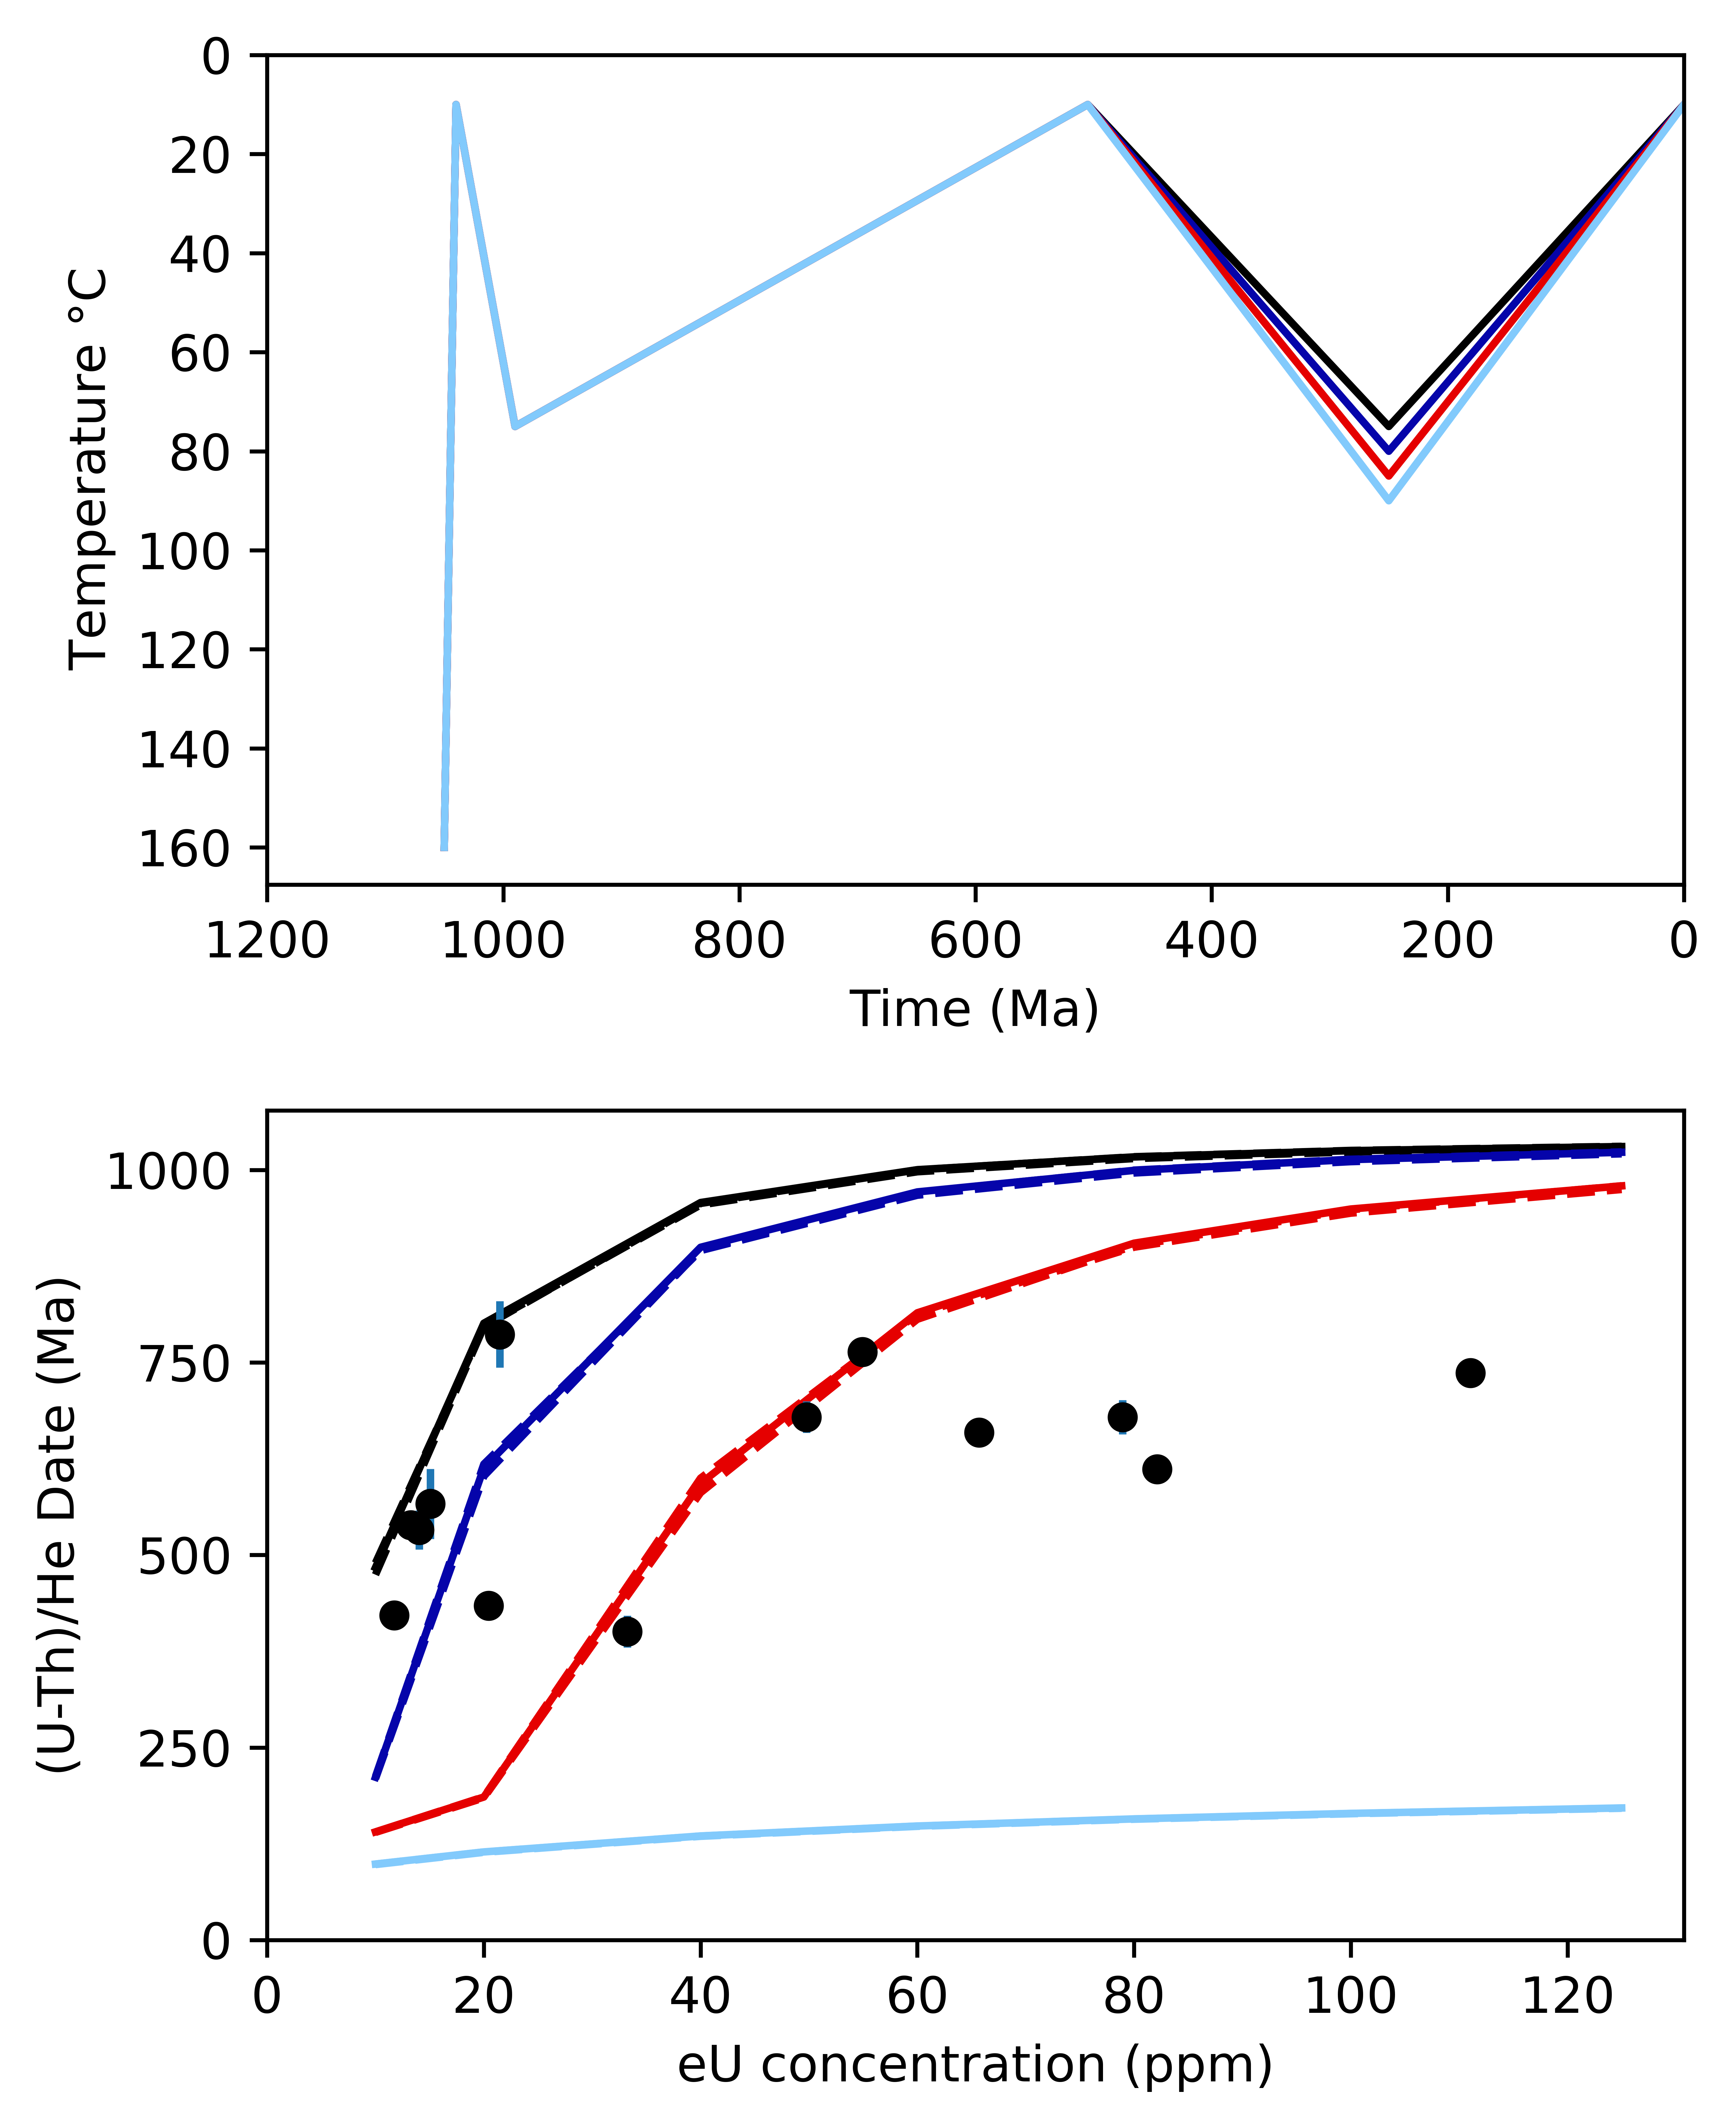

In [67]:
ap_paths = pyt.tT_model(ap_grain_in,tT_ap_phan,ap_obs_data)
ap_fig = ap_paths.forward(log2_nodes=7)

ax_1 = ap_fig.axes[0]
ax_1.autoscale()
ax_1.set_xlim(right=0)
ax_1.xaxis.set_ticks(np.arange(1200,-1,-200))
ax_1.yaxis.set_ticks(np.arange(160,-1,-20))

ax_2 = ap_fig.axes[1]
ax_2.autoscale()
ax_2.xaxis.set_ticks(np.arange(0,140,20))
ax_2.yaxis.set_ticks(np.arange(0,1250,250))

ap_fig.savefig('figures/ap_forward_phan.png',bbox_inches='tight')

This set of tT paths tests amount of reheating in the Neoproterozoic at 990 Ma (Jacobsville):

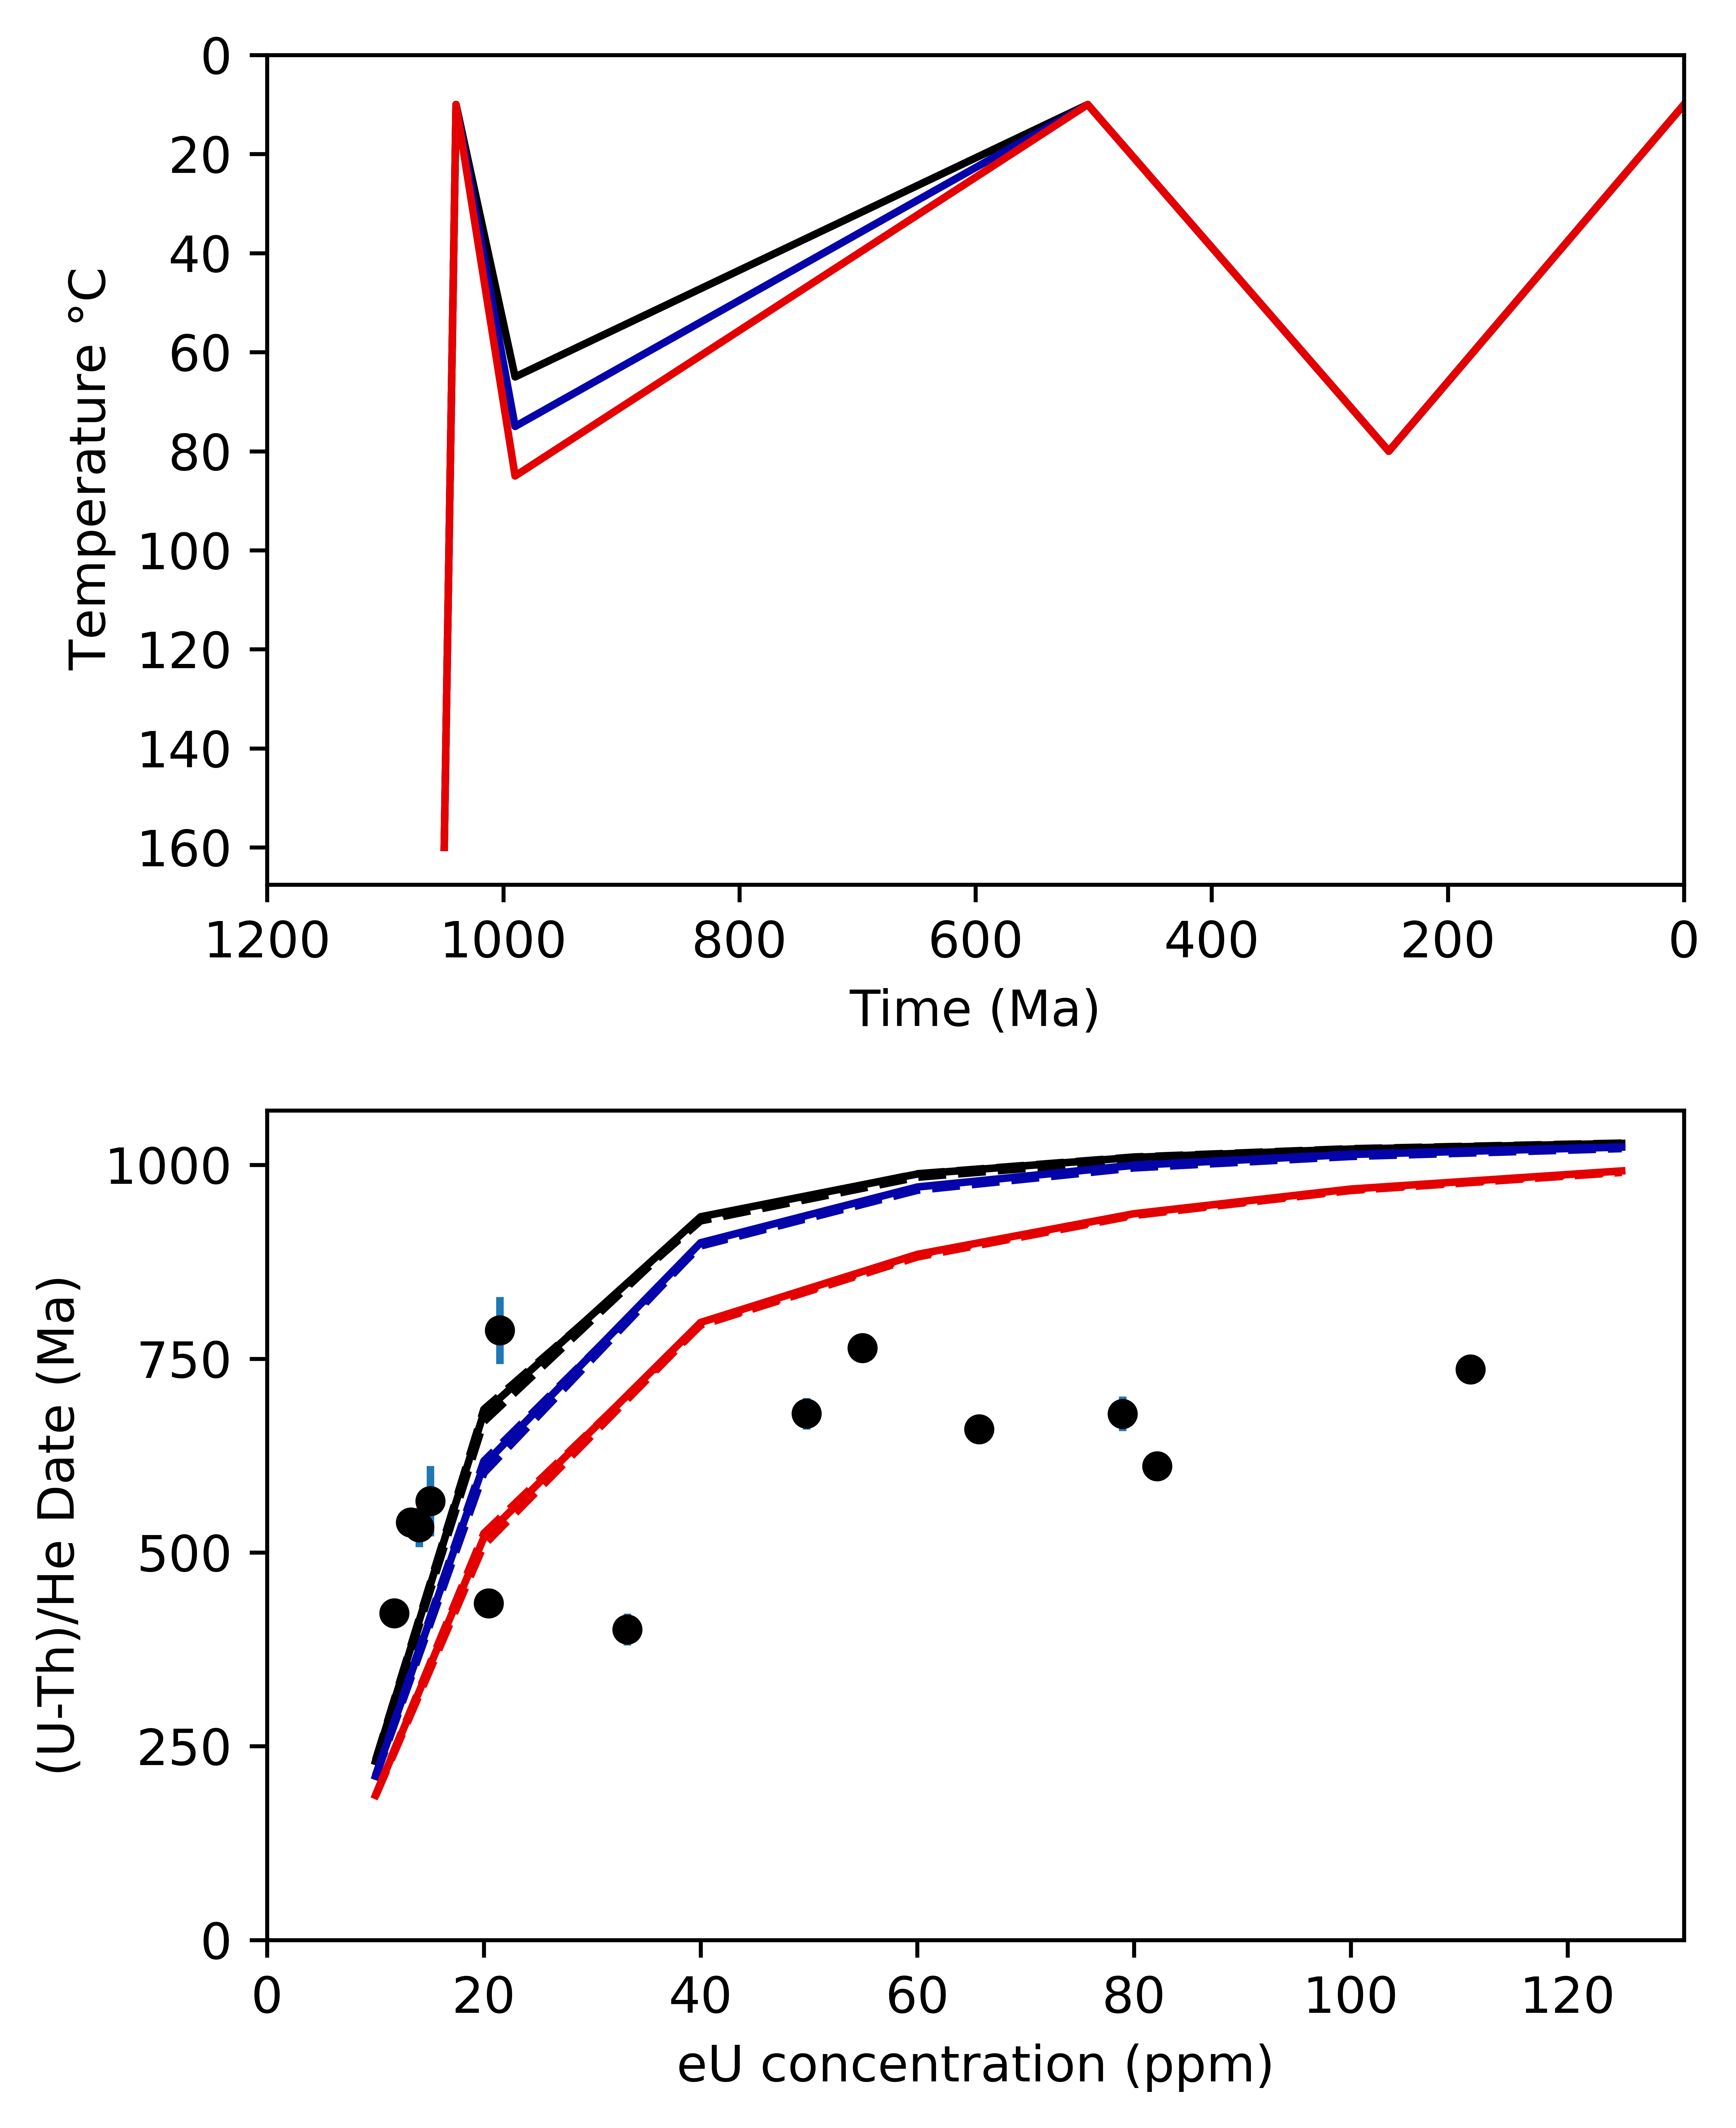

In [68]:
ap_paths = pyt.tT_model(ap_grain_in,tT_ap_neo_heat,ap_obs_data)
ap_fig = ap_paths.forward(log2_nodes=7)

ax_1 = ap_fig.axes[0]
ax_1.autoscale()
ax_1.set_xlim(right=0)
ax_1.xaxis.set_ticks(np.arange(1200,-1,-200))
ax_1.yaxis.set_ticks(np.arange(160,-1,-20))

ax_2 = ap_fig.axes[1]
ax_2.autoscale()
ax_2.xaxis.set_ticks(np.arange(0,140,20))
ax_2.yaxis.set_ticks(np.arange(0,1250,250))

ap_fig.savefig('figures/ap_forward_neo_heat.png',bbox_inches='tight')

Here, we adjust the influence of the timing of Neoproterozoic cooling following reheating. The amount of reheating is held constant at 75 $\degree$ C

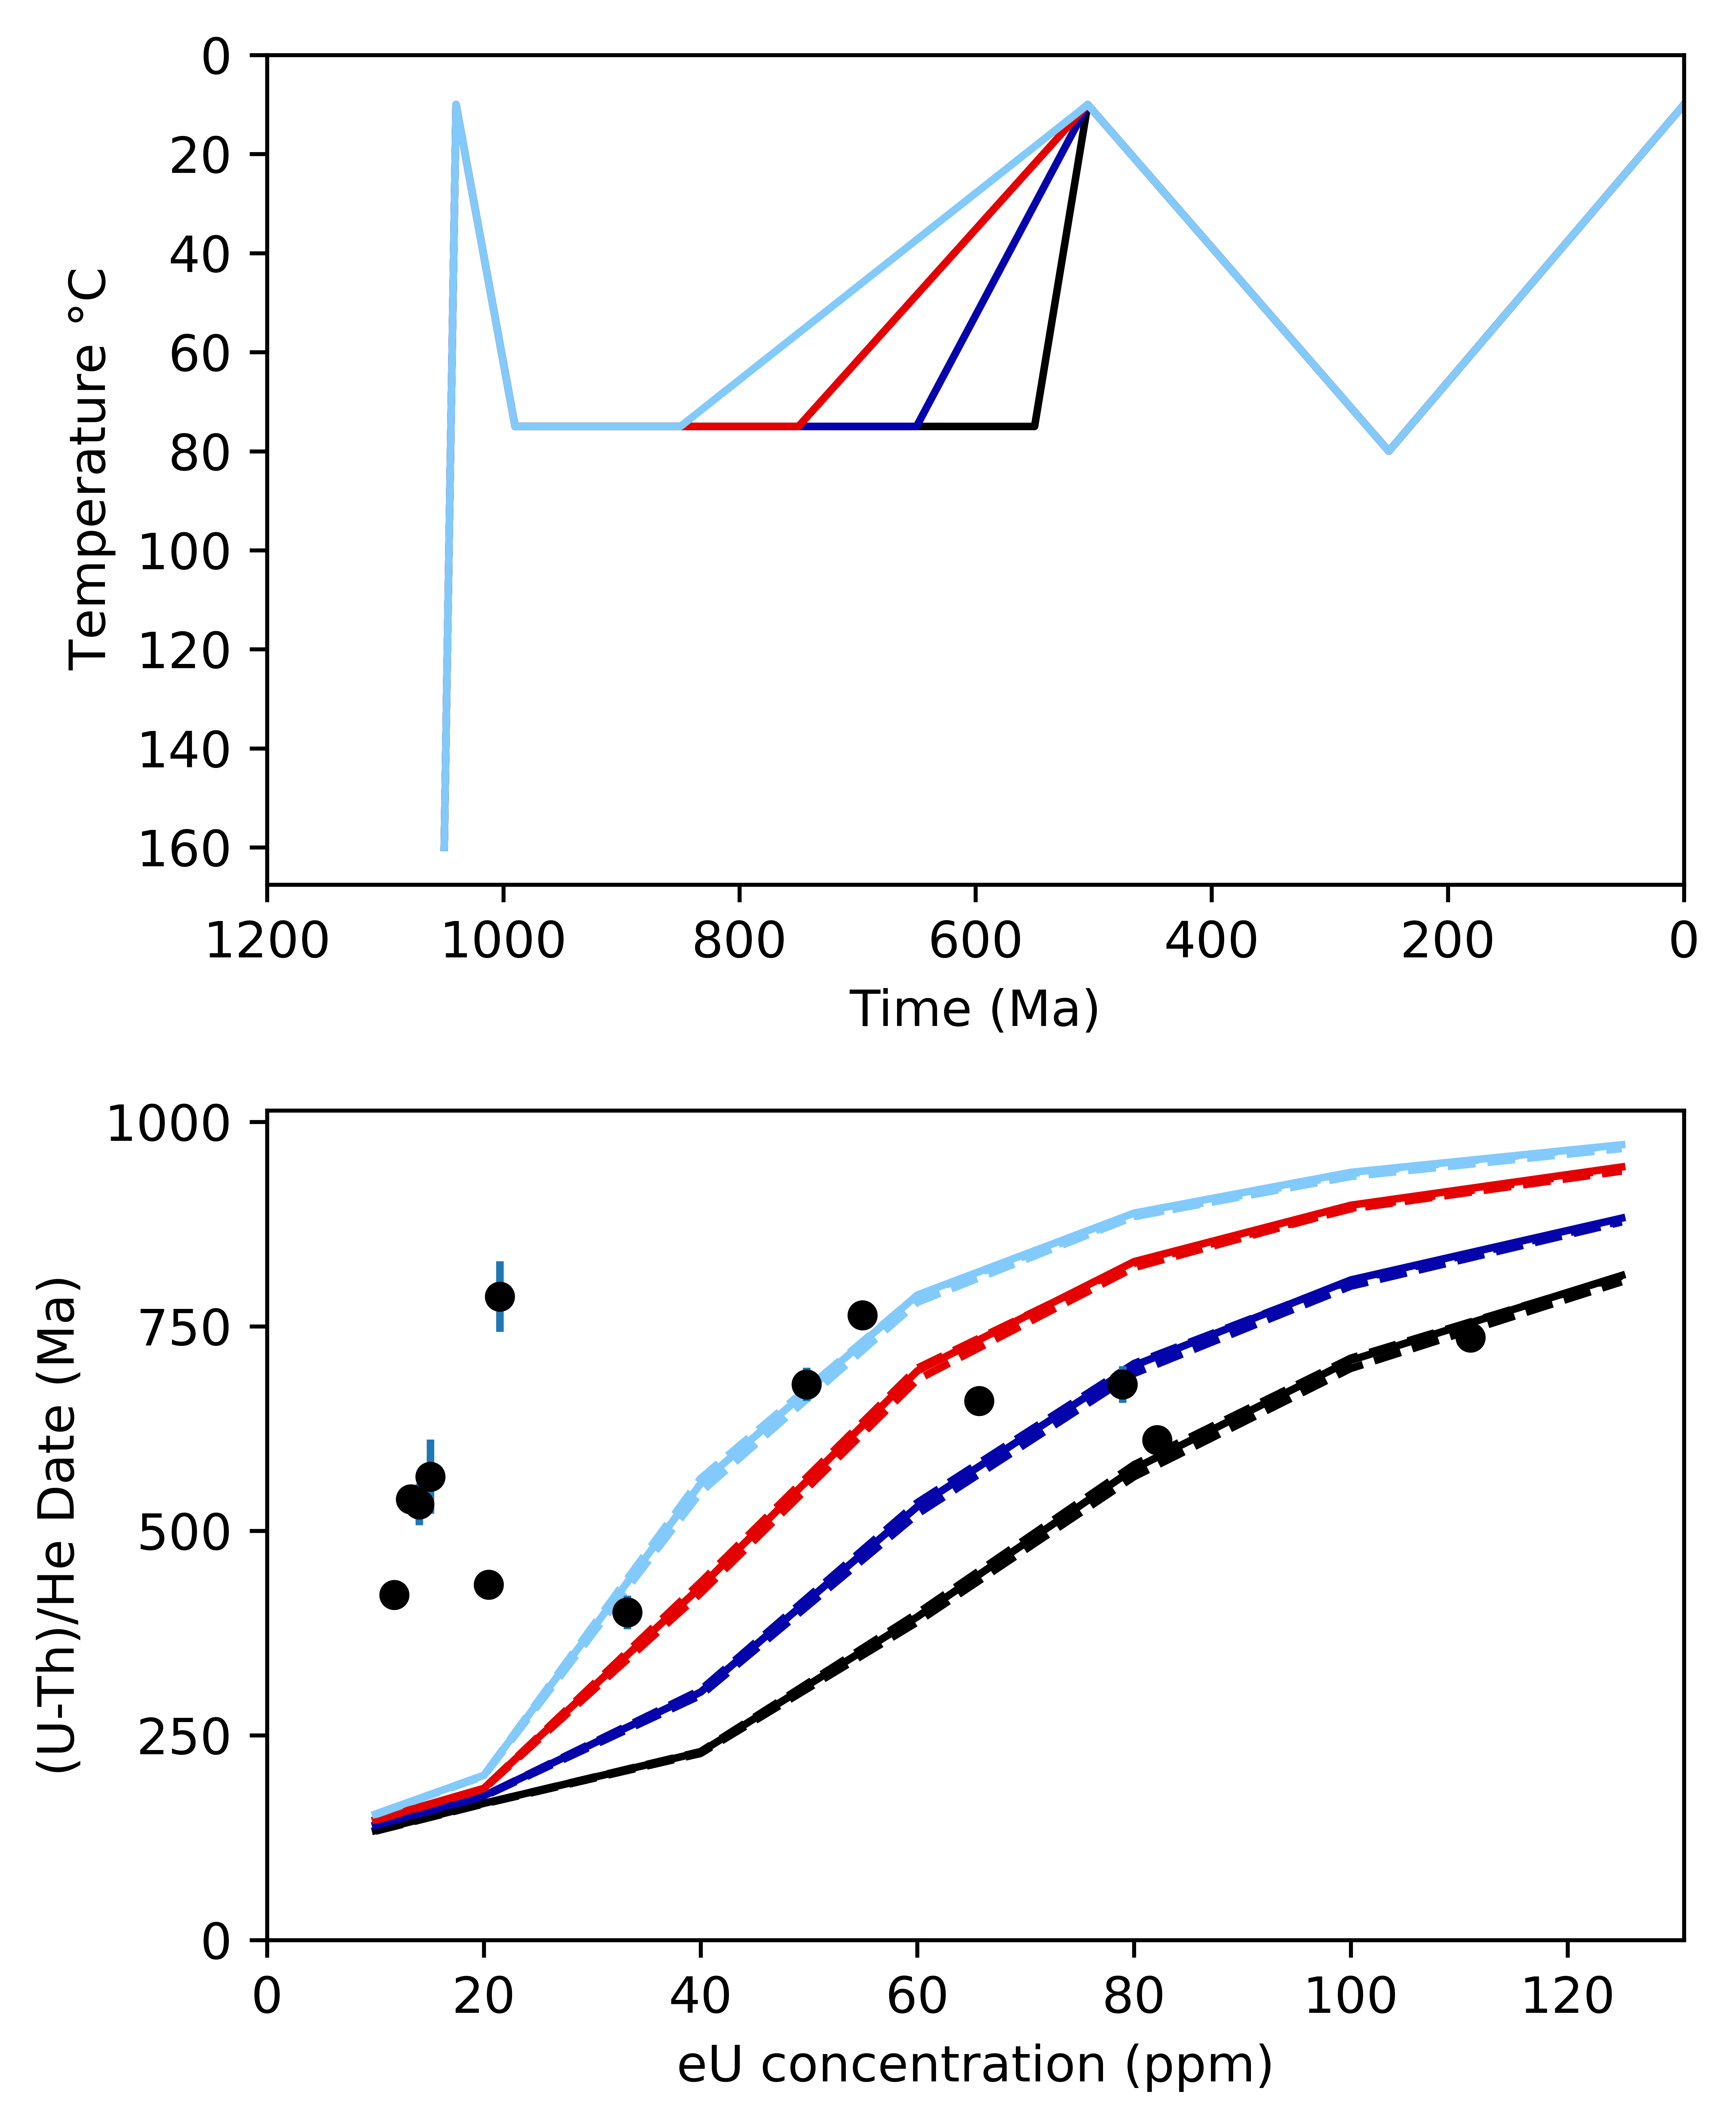

In [71]:
ap_paths = pyt.tT_model(ap_grain_in,tT_ap_neo_cool,ap_obs_data)
ap_fig = ap_paths.forward(log2_nodes=7)

ax_1 = ap_fig.axes[0]
ax_1.autoscale()
ax_1.set_xlim(right=0)
ax_1.xaxis.set_ticks(np.arange(1200,-1,-200))
ax_1.yaxis.set_ticks(np.arange(160,-1,-20))

ax_2 = ap_fig.axes[1]
ax_2.autoscale()
ax_2.xaxis.set_ticks(np.arange(0,140,20))
ax_2.yaxis.set_ticks(np.arange(0,1250,250))

ap_fig.savefig('figures/ap_forward_neo_cool.png',bbox_inches='tight')

Finally, we combine tests of maximum Neoproterozoic reheating amount and timing of Neoproterozoic cooling with three examples. One with cooling starting at 550 Ma:

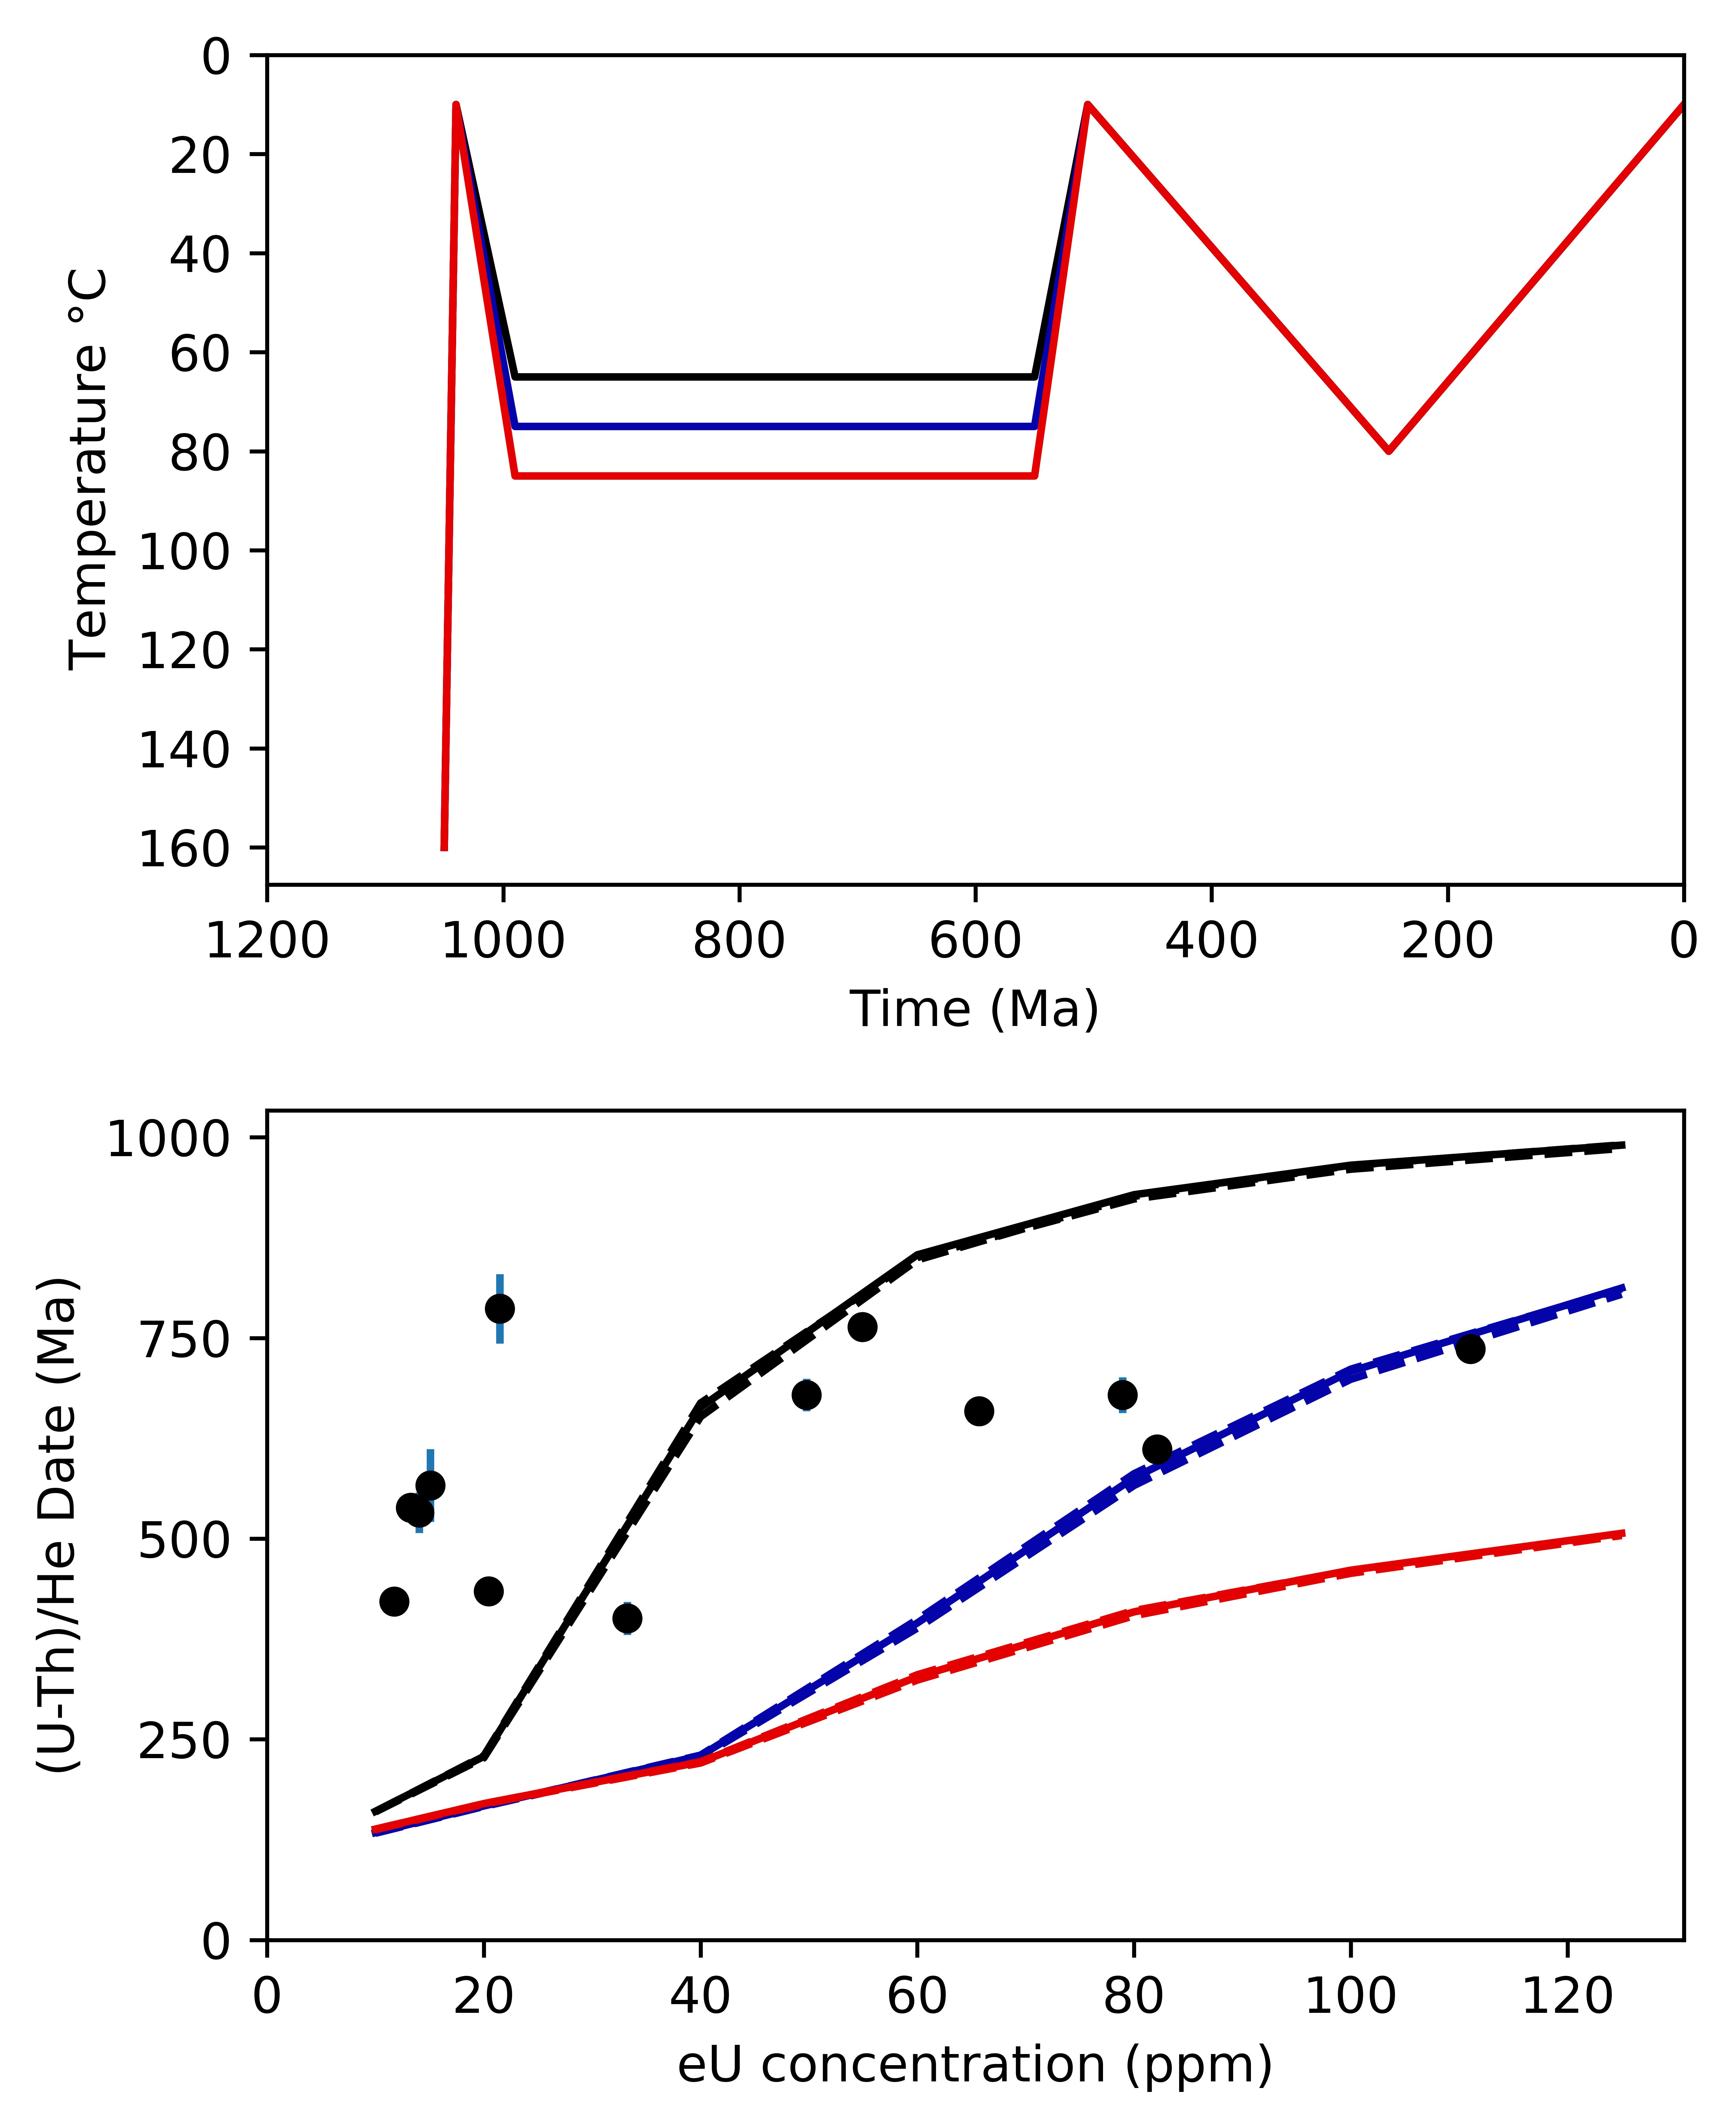

In [72]:
ap_paths = pyt.tT_model(ap_grain_in,tT_ap_550Ma,ap_obs_data)
ap_fig = ap_paths.forward(log2_nodes=7)

ax_1 = ap_fig.axes[0]
ax_1.autoscale()
ax_1.set_xlim(right=0)
ax_1.xaxis.set_ticks(np.arange(1200,-1,-200))
ax_1.yaxis.set_ticks(np.arange(160,-1,-20))

ax_2 = ap_fig.axes[1]
ax_2.autoscale()
ax_2.xaxis.set_ticks(np.arange(0,140,20))
ax_2.yaxis.set_ticks(np.arange(0,1250,250))

ap_fig.savefig('figures/ap_forward_550Ma.png',bbox_inches='tight')

One at 750 Ma:

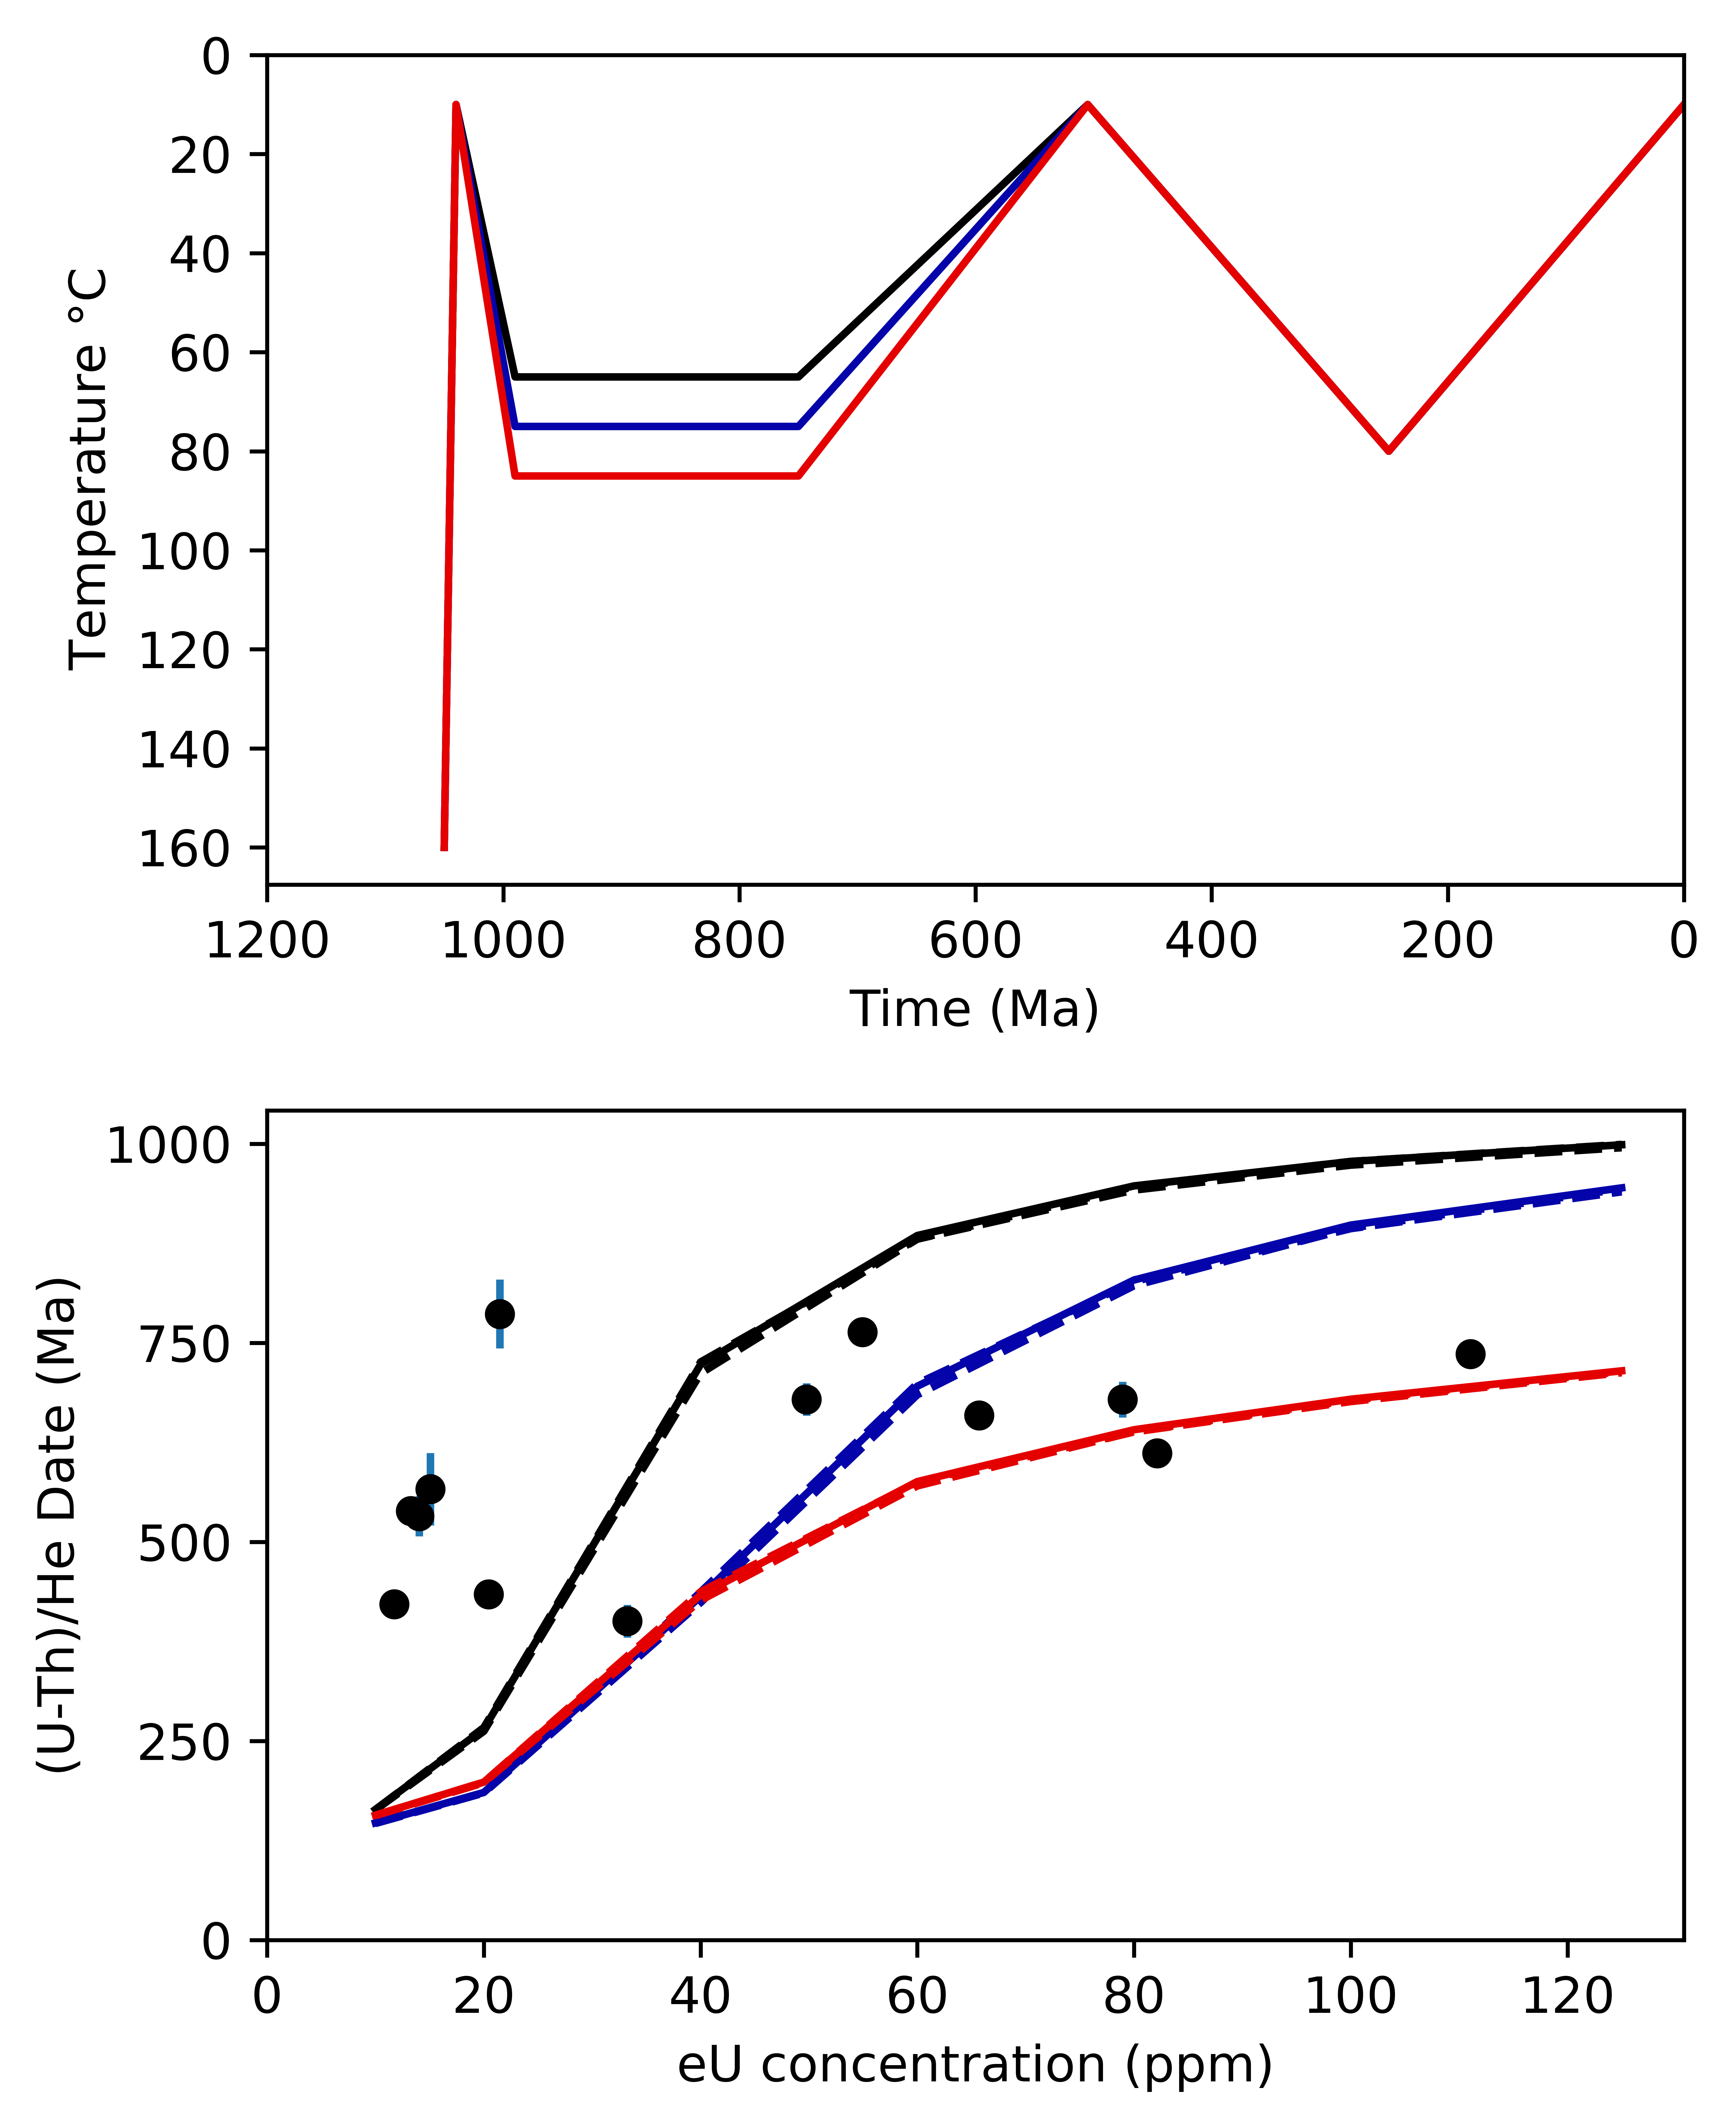

In [73]:
ap_paths = pyt.tT_model(ap_grain_in,tT_ap_750Ma,ap_obs_data)
ap_fig = ap_paths.forward(log2_nodes=7)

ax_1 = ap_fig.axes[0]
ax_1.autoscale()
ax_1.set_xlim(right=0)
ax_1.xaxis.set_ticks(np.arange(1200,-1,-200))
ax_1.yaxis.set_ticks(np.arange(160,-1,-20))

ax_2 = ap_fig.axes[1]
ax_2.autoscale()
ax_2.xaxis.set_ticks(np.arange(0,140,20))
ax_2.yaxis.set_ticks(np.arange(0,1250,250))

ap_fig.savefig('figures/ap_forward_750Ma.png',bbox_inches='tight')

And one with cooling starting at 850 Ma:

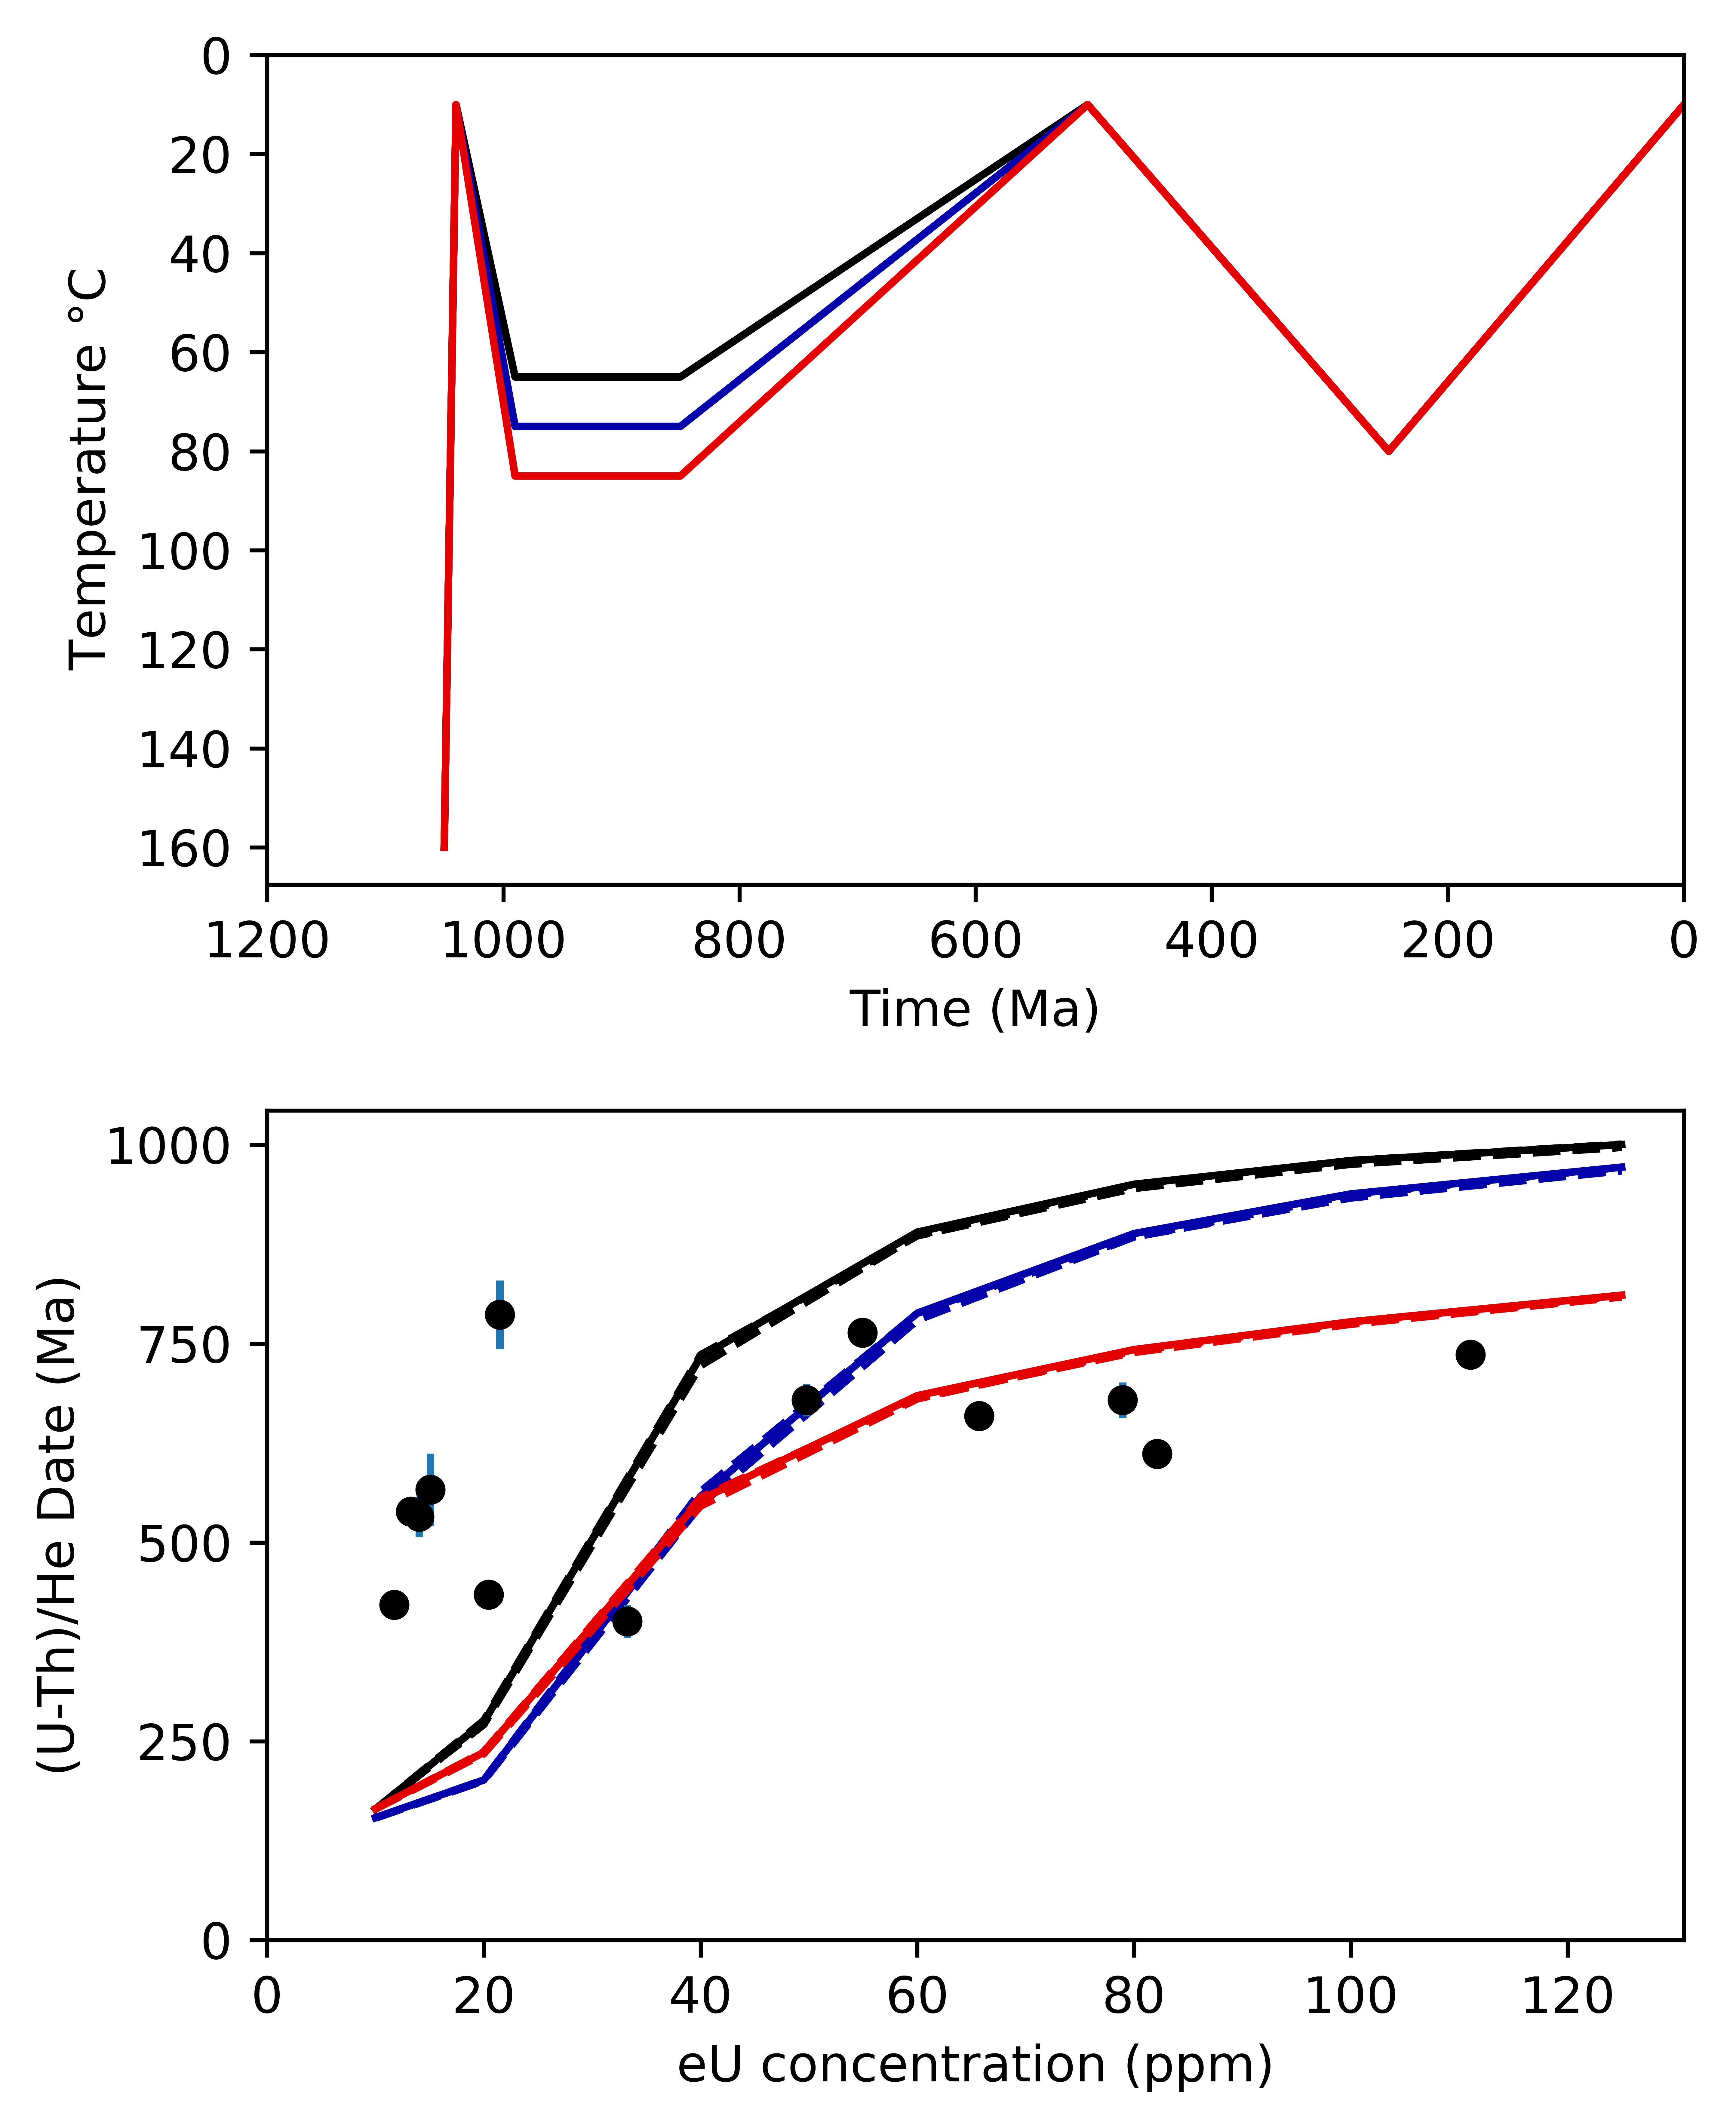

In [75]:
ap_paths = pyt.tT_model(ap_grain_in,tT_ap_850Ma,ap_obs_data)
ap_fig = ap_paths.forward(log2_nodes=7)

ax_1 = ap_fig.axes[0]
ax_1.autoscale()
ax_1.set_xlim(right=0)
ax_1.xaxis.set_ticks(np.arange(1200,-1,-200))
ax_1.yaxis.set_ticks(np.arange(160,-1,-20))

ax_2 = ap_fig.axes[1]
ax_2.autoscale()
ax_2.xaxis.set_ticks(np.arange(0,140,20))
ax_2.yaxis.set_ticks(np.arange(0,1250,250))

ap_fig.savefig('figures/ap_forward_850Ma.png',bbox_inches='tight')

#### Zircon forward models

In [ ]:
zirc_paths = pyt.tT_model(zirc_grain_in,tT_zirc_phan,zirc_obs_data)
zirc_fig = zirc_paths.forward(log2_nodes=7)
#zirc_fig.savefig('figures/zirc_forward_model.png',bbox_inches='tight')